In [25]:
from pathlib import Path

data_dir = Path("../data/raw/dataset-resized")

classes = [folder.name for folder in data_dir.iterdir() if folder.is_dir()]

print("Classes:")
print(classes)

for class_name in classes:
    class_path = data_dir / class_name
    images = list(class_path.glob("*"))
    print(f"{class_name}: {len(images)} images")

Classes:
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images


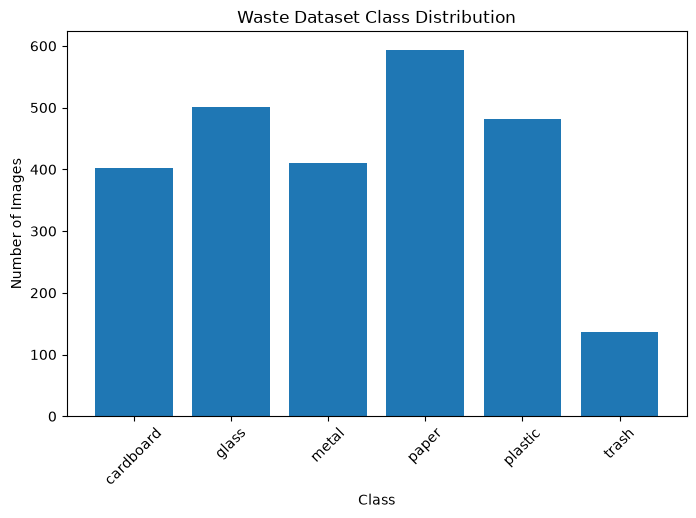

In [26]:
import matplotlib.pyplot as plt

class_counts = []

for class_name in classes:
    class_path = data_dir / class_name
    count = len(list(class_path.glob("*")))
    class_counts.append(count)

plt.figure(figsize=(8, 5))
plt.bar(classes, class_counts)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Waste Dataset Class Distribution")
plt.xticks(rotation=45)
plt.show()

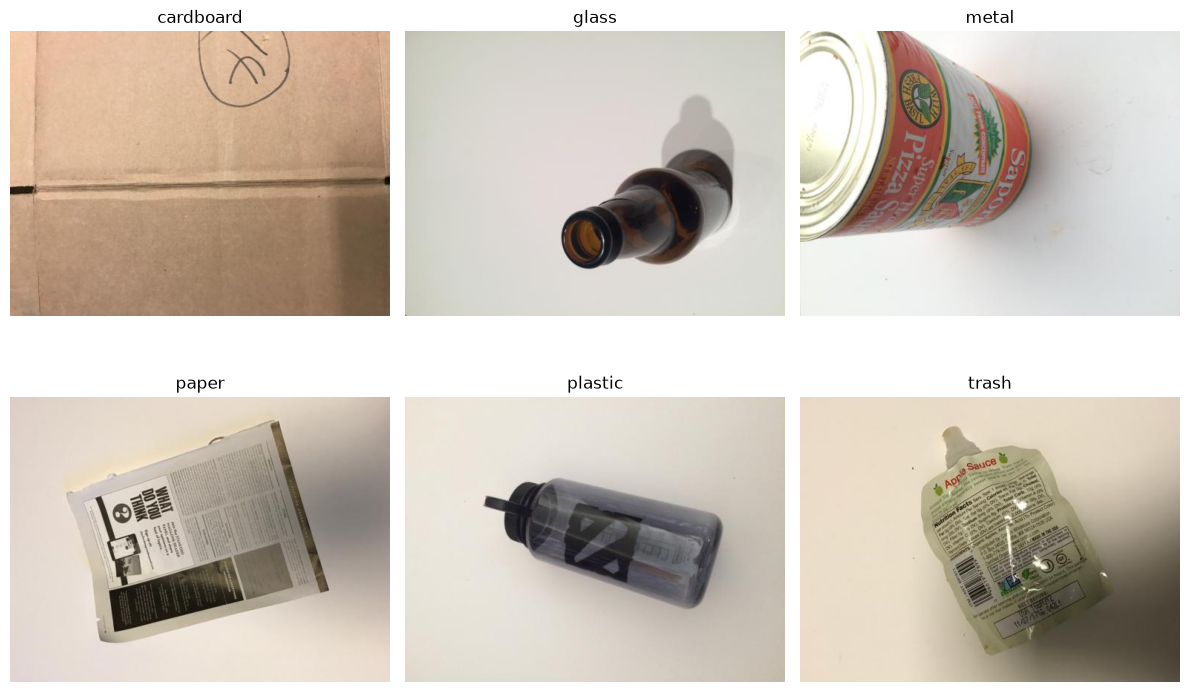

In [27]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.ravel(), classes):
    image_path = list((data_dir / class_name).glob("*"))[0]
    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
from collections import Counter
from PIL import Image

image_sizes = []

for class_name in classes:
    class_path = data_dir / class_name

    for image_path in class_path.glob("*"):
        with Image.open(image_path) as image:
            image_sizes.append(image.size)

size_counts = Counter(image_sizes)

print("Number of unique image sizes:", len(size_counts))
print("\nMost common sizes:")

for size, count in size_counts.most_common(10):
    print(size, "->", count, "images")

Number of unique image sizes: 1

Most common sizes:
(512, 384) -> 2527 images


In [29]:
from torchvision import datasets

dataset = datasets.ImageFolder(data_dir)

print("Number of images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)

Number of images: 2527
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Class mapping: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


In [42]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    data_dir,
    transform=transform
)

image, label = dataset[0]

print("Image type:", type(image))
print("Image shape:", image.shape)
print("Label:", label)

Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 128, 128])
Label: 0


In [31]:
from sklearn.model_selection import train_test_split

indices = list(range(len(dataset)))
labels = [label for _, label in dataset.samples]

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Total:", len(dataset))
print("Training:", len(train_indices))
print("Validation:", len(val_indices))

Total: 2527
Training: 2021
Validation: 506


In [44]:
train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

images, labels = next(iter(train_loader))


print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Training samples: 2021
Validation samples: 506
Images shape: torch.Size([32, 3, 128, 128])
Labels shape: torch.Size([32])


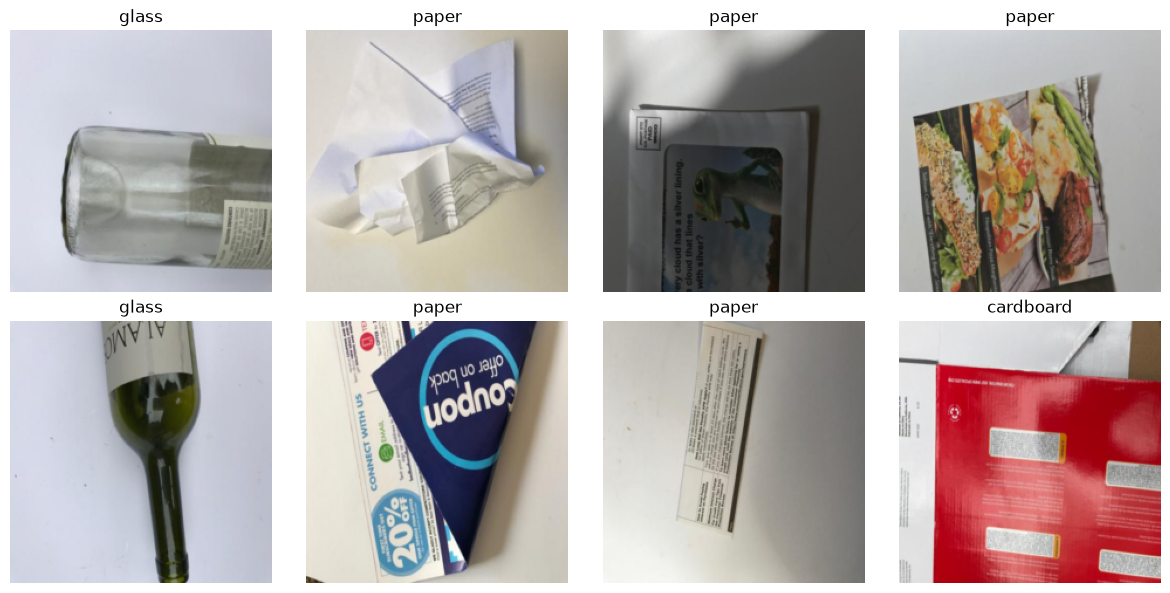

In [34]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.ravel()):
    image = images[i].permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(dataset.classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

print(project_root)

d:\AI-Engineer_Tutorial\Week-02\waste-image-classifier


In [50]:
import importlib
import src.model

importlib.reload(src.model)

WasteClassifier = src.model.WasteClassifier

model = WasteClassifier()

print(model)

WasteClassifier(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=6, bias=True)
  )
)


In [52]:
import torch

from src.model import WasteClassifier

model = WasteClassifier()

print(model)

images, labels = next(iter(train_loader))

output = model(images)

print("Input shape:", images.shape)
print("Output shape:", output.shape)

WasteClassifier(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=6, bias=True)
  )
)
Input shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32, 6])


In [53]:
import torch
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(loss_fn)
print(optimizer)



CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [54]:
images, labels = next(iter(train_loader))

# Before training
outputs = model(images)
loss_before = loss_fn(outputs, labels)

print("Loss before training:", loss_before.item())

# Training step
optimizer.zero_grad()
loss_before.backward()
optimizer.step()

# After one weight update
outputs = model(images)
loss_after = loss_fn(outputs, labels)

print("Loss after one update:", loss_after.item())

Loss before training: 1.8042449951171875
Loss after one update: 1.7019706964492798


In [57]:
model.train()

for images, labels in train_loader:

    outputs = model(images)

    loss = loss_fn(outputs, labels)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

print("Training loss:", loss.item())

Training loss: 0.7041410207748413


In [58]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total

print("Validation accuracy:", accuracy)

Validation accuracy: 0.49407114624505927


In [59]:
for epoch in range(3):

    # Training
    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total

    print(
        f"Epoch {epoch + 1}/3 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

Epoch 1/3 | Train Loss: 1.1334 | Validation Accuracy: 0.5198
Epoch 2/3 | Train Loss: 1.0337 | Validation Accuracy: 0.5553
Epoch 3/3 | Train Loss: 0.8910 | Validation Accuracy: 0.5889


In [60]:
from sklearn.metrics import confusion_matrix
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[ 61   8   0   7   5   0]
 [  4  77   0   9  10   0]
 [  6  33  15  21   6   1]
 [  2  10   3 100   4   0]
 [  7  27   2  18  43   0]
 [  3  14   1   7   0   2]]


In [61]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=dataset.classes
    )
)

              precision    recall  f1-score   support

   cardboard       0.73      0.75      0.74        81
       glass       0.46      0.77      0.57       100
       metal       0.71      0.18      0.29        82
       paper       0.62      0.84      0.71       119
     plastic       0.63      0.44      0.52        97
       trash       0.67      0.07      0.13        27

    accuracy                           0.59       506
   macro avg       0.64      0.51      0.50       506
weighted avg       0.63      0.59      0.55       506



In [63]:
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "waste_classifier_v1.pth"

torch.save(model.state_dict(), model_path)

print(f"Model saved to: {model_path}")

print(model_path.exists())
print(model_path)

Model saved to: ..\models\waste_classifier_v1.pth
True
..\models\waste_classifier_v1.pth
